In [ ]:
# ==============================================================================
# CELL 1: EXPORT ROUND-2 BLIND SWAPPED WORKBOOKS (READ-ONLY ON EXISTING FILES)
# ==============================================================================
from google.colab import drive
import os, pandas as pd, openpyxl
from openpyxl.styles import Font, PatternFill, Alignment, Border, Side
from openpyxl.worksheet.datavalidation import DataValidation

drive.mount('/content/drive')

GOLD_DIR   = '/content/drive/MyDrive/AffectFusion_Day3/02_gold_verification'
ROUND2_DIR = os.path.join(GOLD_DIR, 'round2_blind_swap')
os.makedirs(ROUND2_DIR, exist_ok=True)

# Existing Round-1 Excel files (READ-ONLY — never renamed or modified)
R1_RAGIB_TEST = os.path.join(GOLD_DIR, 'gold_member1_ragib_1500rows.xlsx')
R1_GALIB_TEST = os.path.join(GOLD_DIR, 'gold_member2_galib_1500rows.xlsx')
R1_RAGIB_VAL  = os.path.join(GOLD_DIR, 'gold2_val_member1_ragib_1000rows.xlsx')
R1_GALIB_VAL  = os.path.join(GOLD_DIR, 'gold2_val_member2_galib_1000rows.xlsx')

# New Round-2 Blind Swapped Excel files
R2_FOR_RAGIB  = os.path.join(ROUND2_DIR, 'round2_blind_for_ragib_2500rows.xlsx')
R2_FOR_GALIB  = os.path.join(ROUND2_DIR, 'round2_blind_for_galib_2500rows.xlsx')

def write_blind_xlsx(df_rows: pd.DataFrame, out_path: str, title: str):
    if os.path.exists(out_path):
        print(f"[SKIP] Already exists (preserving your work): {out_path}")
        return
    wb = openpyxl.Workbook()
    ws = wb.active
    ws.title = "Manual_Annotation"

    ws_ref = wb.create_sheet("Rubric_Guide")
    rubric = [
        ("Emotion Class", "Quick Annotation Definition"),
        ("Joy",          "Genuine happiness, praise, love, gratitude, pride, celebration, genuine laughter"),
        ("Neutral",      "Objective facts, plain questions, timestamps, announcements, flat statements"),
        ("Anger",        "Outrage, hostility, strong complaints, demanding punishment/boycott, cursing"),
        ("Sadness",      "Grief, heartbreak, missing someone/pet, sympathy, condolences, regret"),
        ("Surprise",     "Genuine shock, astonishment, disbelief, unexpected plot twist or realization"),
        ("Sarcasm",      "Irony, mockery, passive-aggressive praise, or ironic emoji-text contradiction"),
        ("Fear",         "Genuine dread, terror, anxiety, horror, worry, warning of danger/disaster"),
        ("Disgust",      "Revulsion, calling something gross/cringe/corrupt/scam/shameless/faltu/ghrina"),
        ("Anticipation", "Looking forward to something, hype, waiting eagerly, requesting next part/episode"),
    ]
    for r_i, (k, v) in enumerate(rubric, start=1):
        ws_ref.cell(row=r_i, column=1, value=k)
        ws_ref.cell(row=r_i, column=2, value=v)
        if r_i == 1:
            for c_i in (1, 2):
                ws_ref.cell(row=r_i, column=c_i).font = Font(bold=True, color="FFFFFF")
                ws_ref.cell(row=r_i, column=c_i).fill = PatternFill("solid", fgColor="1F2A44")
    ws_ref.column_dimensions["A"].width = 18
    ws_ref.column_dimensions["B"].width = 88

    headers = ["sample_no", "row_id", "source_split", "lang", "has_emoji", "clean_text", "emojis", "human_label", "notes_optional"]
    ws.append(headers)
    h_fill  = PatternFill("solid", fgColor="1F2A44")
    h_font  = Font(bold=True, color="FFFFFF", size=11)
    in_fill = PatternFill("solid", fgColor="FFF9E6")
    zb_fill = PatternFill("solid", fgColor="F5F7FA")
    bdr = Border(left=Side(style="thin", color="D0D7DE"), right=Side(style="thin", color="D0D7DE"),
                 top=Side(style="thin", color="D0D7DE"), bottom=Side(style="thin", color="D0D7DE"))

    for c_i in range(1, len(headers) + 1):
        cell = ws.cell(row=1, column=c_i)
        cell.fill, cell.font, cell.border = h_fill, h_font, bdr
        cell.alignment = Alignment(horizontal="center", vertical="center")
    ws.row_dimensions[1].height = 24

    for idx, r in enumerate(df_rows.itertuples(index=False), start=1):
        r_num = idx + 1
        ws.append([idx, r.row_id, r.source_split, r.lang, r.has_emoji, r.clean_text, "" if pd.isna(r.emojis) else r.emojis, "", ""])
        for c_i in range(1, len(headers) + 1):
            cell = ws.cell(row=r_num, column=c_i)
            cell.border = bdr
            if c_i == 8:
                cell.fill = in_fill
                cell.alignment = Alignment(horizontal="center", vertical="center")
            elif idx % 2 == 0:
                cell.fill = zb_fill
            if c_i == 6:
                cell.alignment = Alignment(wrap_text=True, vertical="top")
            elif c_i in (1, 2, 3, 4, 5, 7):
                cell.alignment = Alignment(horizontal="center", vertical="center")

    dv = DataValidation(type="list", formula1="=Rubric_Guide!$A$2:$A$10", allow_blank=True)
    ws.add_data_validation(dv)
    dv.add(f"H2:H{len(df_rows) + 1}")

    for col_l, w in {"A": 11, "B": 14, "C": 12, "D": 8, "E": 11, "F": 72, "G": 14, "H": 18, "I": 24}.items():
        ws.column_dimensions[col_l].width = w
    ws.freeze_panes = "A2"
    ws.auto_filter.ref = f"A1:I{len(df_rows) + 1}"
    wb.save(out_path)
    print(f"[SAVED] {title}: {out_path} ({len(df_rows):,} rows)")

# Read Round-1 sets (dropping existing human_label so Round 2 is 100% blind)
base_cols = ["row_id", "lang", "has_emoji", "clean_text", "emojis"]

ragib_r1 = pd.concat([
    pd.read_excel(R1_RAGIB_TEST, sheet_name="Manual_Annotation")[base_cols].assign(source_split="test_3k"),
    pd.read_excel(R1_RAGIB_VAL,  sheet_name="Manual_Annotation")[base_cols].assign(source_split="val_3k"),
], ignore_index=True).sample(frac=1.0, random_state=101).reset_index(drop=True)

galib_r1 = pd.concat([
    pd.read_excel(R1_GALIB_TEST, sheet_name="Manual_Annotation")[base_cols].assign(source_split="test_3k"),
    pd.read_excel(R1_GALIB_VAL,  sheet_name="Manual_Annotation")[base_cols].assign(source_split="val_3k"),
], ignore_index=True).sample(frac=1.0, random_state=202).reset_index(drop=True)

# Swap: Galib's Round-1 rows go blind to Ragib; Ragib's Round-1 rows go blind to Galib
write_blind_xlsx(galib_r1, R2_FOR_RAGIB, "Round-2 Blind Swap FOR Ragib (2,500 rows)")
write_blind_xlsx(ragib_r1, R2_FOR_GALIB, "Round-2 Blind Swap FOR Galib (2,500 rows)")

Mounted at /content/drive
[SAVED] Round-2 Blind Swap FOR Ragib (2,500 rows): /content/drive/MyDrive/AffectFusion_Day3/02_gold_verification/round2_blind_swap/round2_blind_for_ragib_2500rows.xlsx (2,500 rows)
[SAVED] Round-2 Blind Swap FOR Galib (2,500 rows): /content/drive/MyDrive/AffectFusion_Day3/02_gold_verification/round2_blind_swap/round2_blind_for_galib_2500rows.xlsx (2,500 rows)


In [ ]:
# ==============================================================================
# CELL 1: EXPORT ROUND-2 BLIND SWAPPED WORKBOOKS (READ-ONLY ON EXISTING FILES)
# ==============================================================================
from google.colab import drive
import os, pandas as pd, openpyxl
from openpyxl.styles import Font, PatternFill, Alignment, Border, Side
from openpyxl.worksheet.datavalidation import DataValidation

drive.mount('/content/drive')

GOLD_DIR   = '/content/drive/MyDrive/AffectFusion_Day3/02_gold_verification'
ROUND2_DIR = os.path.join(GOLD_DIR, 'round2_blind_swap')
os.makedirs(ROUND2_DIR, exist_ok=True)

# Existing Round-1 Excel files (READ-ONLY — never renamed or modified)
R1_RAGIB_TEST = os.path.join(GOLD_DIR, 'gold_member1_ragib_1500rows.xlsx')
R1_GALIB_TEST = os.path.join(GOLD_DIR, 'gold_member2_galib_1500rows.xlsx')
R1_RAGIB_VAL  = os.path.join(GOLD_DIR, 'gold2_val_member1_ragib_1000rows.xlsx')
R1_GALIB_VAL  = os.path.join(GOLD_DIR, 'gold2_val_member2_galib_1000rows.xlsx')

# New Round-2 Blind Swapped Excel files
R2_FOR_RAGIB  = os.path.join(ROUND2_DIR, 'round2_blind_for_ragib_2500rows.xlsx')
R2_FOR_GALIB  = os.path.join(ROUND2_DIR, 'round2_blind_for_galib_2500rows.xlsx')

def write_blind_xlsx(df_rows: pd.DataFrame, out_path: str, title: str):
    if os.path.exists(out_path):
        print(f"[SKIP] Already exists (preserving your work): {out_path}")
        return
    wb = openpyxl.Workbook()
    ws = wb.active
    ws.title = "Manual_Annotation"

    ws_ref = wb.create_sheet("Rubric_Guide")
    rubric = [
        ("Emotion Class", "Quick Annotation Definition"),
        ("Joy",          "Genuine happiness, praise, love, gratitude, pride, celebration, genuine laughter"),
        ("Neutral",      "Objective facts, plain questions, timestamps, announcements, flat statements"),
        ("Anger",        "Outrage, hostility, strong complaints, demanding punishment/boycott, cursing"),
        ("Sadness",      "Grief, heartbreak, missing someone/pet, sympathy, condolences, regret"),
        ("Surprise",     "Genuine shock, astonishment, disbelief, unexpected plot twist or realization"),
        ("Sarcasm",      "Irony, mockery, passive-aggressive praise, or ironic emoji-text contradiction"),
        ("Fear",         "Genuine dread, terror, anxiety, horror, worry, warning of danger/disaster"),
        ("Disgust",      "Revulsion, calling something gross/cringe/corrupt/scam/shameless/faltu/ghrina"),
        ("Anticipation", "Looking forward to something, hype, waiting eagerly, requesting next part/episode"),
    ]
    for r_i, (k, v) in enumerate(rubric, start=1):
        ws_ref.cell(row=r_i, column=1, value=k)
        ws_ref.cell(row=r_i, column=2, value=v)
        if r_i == 1:
            for c_i in (1, 2):
                ws_ref.cell(row=r_i, column=c_i).font = Font(bold=True, color="FFFFFF")
                ws_ref.cell(row=r_i, column=c_i).fill = PatternFill("solid", fgColor="1F2A44")
    ws_ref.column_dimensions["A"].width = 18
    ws_ref.column_dimensions["B"].width = 88

    headers = ["sample_no", "row_id", "source_split", "lang", "has_emoji", "clean_text", "emojis", "human_label", "notes_optional"]
    ws.append(headers)
    h_fill  = PatternFill("solid", fgColor="1F2A44")
    h_font  = Font(bold=True, color="FFFFFF", size=11)
    in_fill = PatternFill("solid", fgColor="FFF9E6")
    zb_fill = PatternFill("solid", fgColor="F5F7FA")
    bdr = Border(left=Side(style="thin", color="D0D7DE"), right=Side(style="thin", color="D0D7DE"),
                 top=Side(style="thin", color="D0D7DE"), bottom=Side(style="thin", color="D0D7DE"))

    for c_i in range(1, len(headers) + 1):
        cell = ws.cell(row=1, column=c_i)
        cell.fill, cell.font, cell.border = h_fill, h_font, bdr
        cell.alignment = Alignment(horizontal="center", vertical="center")
    ws.row_dimensions[1].height = 24

    for idx, r in enumerate(df_rows.itertuples(index=False), start=1):
        r_num = idx + 1
        ws.append([idx, r.row_id, r.source_split, r.lang, r.has_emoji, r.clean_text, "" if pd.isna(r.emojis) else r.emojis, "", ""])
        for c_i in range(1, len(headers) + 1):
            cell = ws.cell(row=r_num, column=c_i)
            cell.border = bdr
            if c_i == 8:
                cell.fill = in_fill
                cell.alignment = Alignment(horizontal="center", vertical="center")
            elif idx % 2 == 0:
                cell.fill = zb_fill
            if c_i == 6:
                cell.alignment = Alignment(wrap_text=True, vertical="top")
            elif c_i in (1, 2, 3, 4, 5, 7):
                cell.alignment = Alignment(horizontal="center", vertical="center")

    dv = DataValidation(type="list", formula1="=Rubric_Guide!$A$2:$A$10", allow_blank=True)
    ws.add_data_validation(dv)
    dv.add(f"H2:H{len(df_rows) + 1}")

    for col_l, w in {"A": 11, "B": 14, "C": 12, "D": 8, "E": 11, "F": 72, "G": 14, "H": 18, "I": 24}.items():
        ws.column_dimensions[col_l].width = w
    ws.freeze_panes = "A2"
    ws.auto_filter.ref = f"A1:I{len(df_rows) + 1}"
    wb.save(out_path)
    print(f"[SAVED] {title}: {out_path} ({len(df_rows):,} rows)")

# Read Round-1 sets (dropping existing human_label so Round 2 is 100% blind)
base_cols = ["row_id", "lang", "has_emoji", "clean_text", "emojis"]

ragib_r1 = pd.concat([
    pd.read_excel(R1_RAGIB_TEST, sheet_name="Manual_Annotation")[base_cols].assign(source_split="test_3k"),
    pd.read_excel(R1_RAGIB_VAL,  sheet_name="Manual_Annotation")[base_cols].assign(source_split="val_3k"),
], ignore_index=True).sample(frac=1.0, random_state=101).reset_index(drop=True)

galib_r1 = pd.concat([
    pd.read_excel(R1_GALIB_TEST, sheet_name="Manual_Annotation")[base_cols].assign(source_split="test_3k"),
    pd.read_excel(R1_GALIB_VAL,  sheet_name="Manual_Annotation")[base_cols].assign(source_split="val_3k"),
], ignore_index=True).sample(frac=1.0, random_state=202).reset_index(drop=True)

# Swap: Galib's Round-1 rows go blind to Ragib; Ragib's Round-1 rows go blind to Galib
write_blind_xlsx(galib_r1, R2_FOR_RAGIB, "Round-2 Blind Swap FOR Ragib (2,500 rows)")
write_blind_xlsx(ragib_r1, R2_FOR_GALIB, "Round-2 Blind Swap FOR Galib (2,500 rows)")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
[SKIP] Already exists (preserving your work): /content/drive/MyDrive/AffectFusion_Day3/02_gold_verification/round2_blind_swap/round2_blind_for_ragib_2500rows.xlsx
[SKIP] Already exists (preserving your work): /content/drive/MyDrive/AffectFusion_Day3/02_gold_verification/round2_blind_swap/round2_blind_for_galib_2500rows.xlsx


In [ ]:
# ==============================================================================
# CELL 2: COMPUTE HUMAN-vs-HUMAN COHEN'S KAPPA, KRIPPENDORFF'S ALPHA & ADJUDICATION
# ==============================================================================
import os, json, numpy as np, pandas as pd
from sklearn.metrics import cohen_kappa_score, accuracy_score, confusion_matrix

GOLD_DIR   = '/content/drive/MyDrive/AffectFusion_Day3/02_gold_verification'
ROUND2_DIR = os.path.join(GOLD_DIR, 'round2_blind_swap')
LOGS_DIR   = '/content/drive/MyDrive/AffectFusion_Day3/logs'
CLASSES    = ["Joy", "Neutral", "Anger", "Sadness", "Surprise", "Sarcasm", "Fear", "Disgust", "Anticipation"]

def load_labels(path: str, col_out: str, split_tag: str = None) -> pd.DataFrame:
    df = pd.read_excel(path, sheet_name="Manual_Annotation")
    keep = [c for c in ["row_id", "lang", "clean_text", "emojis", "source_split", "human_label"] if c in df.columns]
    df = df[keep].copy()
    if "source_split" not in df.columns and split_tag:
        df["source_split"] = split_tag
    df["human_label"] = df["human_label"].astype(str).str.strip()
    return df[df["human_label"].isin(CLASSES)].rename(columns={"human_label": col_out})

# 1. Gather ALL labels by Annotator 1 (Ragib: Round 1 + Round 2)
ragib_all = pd.concat([
    load_labels(os.path.join(GOLD_DIR,   'gold_member1_ragib_1500rows.xlsx'),     'ragib_label', 'test_3k'),
    load_labels(os.path.join(GOLD_DIR,   'gold2_val_member1_ragib_1000rows.xlsx'),'ragib_label', 'val_3k'),
    load_labels(os.path.join(ROUND2_DIR, 'round2_blind_for_ragib_2500rows.xlsx'), 'ragib_label'),
], ignore_index=True).drop_duplicates(subset=["row_id"], keep="last")

# 2. Gather ALL labels by Annotator 2 (Galib: Round 1 + Round 2)
galib_all = pd.concat([
    load_labels(os.path.join(GOLD_DIR,   'gold_member2_galib_1500rows.xlsx'),     'galib_label', 'test_3k'),
    load_labels(os.path.join(GOLD_DIR,   'gold2_val_member2_galib_1000rows.xlsx'),'galib_label', 'val_3k'),
    load_labels(os.path.join(ROUND2_DIR, 'round2_blind_for_galib_2500rows.xlsx'), 'galib_label'),
], ignore_index=True).drop_duplicates(subset=["row_id"], keep="last")

# 3. Inner join on row_id -> pairs every double-annotated comment automatically
paired = ragib_all[["row_id", "source_split", "lang", "clean_text", "emojis", "ragib_label"]].merge(
    galib_all[["row_id", "galib_label"]], on="row_id", how="inner"
)
assert len(paired) > 0, "No overlapping double-annotated rows found yet! Fill the Round-2 Excel files first."

def krippendorff_alpha_nominal(r1, r2, labels):
    idx_map = {c: i for i, c in enumerate(labels)}
    y1 = np.array([idx_map[x] for x in r1])
    y2 = np.array([idx_map[x] for x in r2])
    n = len(y1)
    d_o = np.mean(y1 != y2)
    counts = np.bincount(np.concatenate([y1, y2]), minlength=len(labels)).astype(float)
    tot = 2.0 * n
    d_e = 1.0 - np.sum(counts * (counts - 1.0)) / (tot * (tot - 1.0))
    return 1.0 if d_e == 0 else float(1.0 - d_o / d_e)

y1, y2 = paired["ragib_label"].tolist(), paired["galib_label"].tolist()
kappa  = float(cohen_kappa_score(y1, y2, labels=CLASSES))
alpha  = krippendorff_alpha_nominal(y1, y2, CLASSES)
raw_ac = float(accuracy_score(y1, y2))
interp = "Almost Perfect" if kappa >= 0.81 else "Substantial" if kappa >= 0.61 else "Moderate" if kappa >= 0.41 else "Fair"

by_lang = {
    lg: {
        "n": int(len(sub)),
        "agreement_pct": round(100.0 * accuracy_score(sub["ragib_label"], sub["galib_label"]), 2),
        "cohens_kappa": round(float(cohen_kappa_score(sub["ragib_label"], sub["galib_label"], labels=CLASSES)), 4),
        "krippendorff_alpha": round(krippendorff_alpha_nominal(sub["ragib_label"], sub["galib_label"], CLASSES), 4),
    }
    for lg in ("ENG", "BN", "BNG") for sub in [paired[paired["lang"] == lg]] if len(sub) >= 10
}

by_split = {
    sp: {
        "n": int(len(sub)),
        "agreement_pct": round(100.0 * accuracy_score(sub["ragib_label"], sub["galib_label"]), 2),
        "cohens_kappa": round(float(cohen_kappa_score(sub["ragib_label"], sub["galib_label"], labels=CLASSES)), 4),
    }
    for sp in ("test_3k", "val_3k") for sub in [paired[paired["source_split"] == sp]] if len(sub) >= 10
}

print("=" * 80)
print(f"HUMAN-vs-HUMAN INTER-ANNOTATOR AGREEMENT ({len(paired):,} / 5,000 paired rows)")
print("=" * 80)
print(f"  Raw Agreement        : {raw_ac * 100:.2f}%")
print(f"  Cohen's Kappa (κ)    : {kappa:.4f}  ({interp} Agreement)")
print(f"  Krippendorff's Alpha : {alpha:.4f}")
print("  By Language          :", json.dumps(by_lang, indent=2))
print("  By Split             :", json.dumps(by_split, indent=2))

display(pd.DataFrame(
    confusion_matrix(y1, y2, labels=CLASSES),
    index=[f"Ragib_{c}" for c in CLASSES],
    columns=[f"Galib_{c}" for c in CLASSES]
))

# 4. Save paired CSV, JSON report, and Disagreements-Only Adjudication Excel sheet
paired["agreed"] = (paired["ragib_label"] == paired["galib_label"]).astype(int)
paired.to_csv(os.path.join(ROUND2_DIR, "human_vs_human_5k_paired.csv"), index=False, encoding="utf-8-sig")

disagree = paired[paired["agreed"] == 0].copy()
disagree["final_consensus_label"] = ""
adj_path = os.path.join(ROUND2_DIR, "disagreements_to_adjudicate.xlsx")
disagree.to_excel(adj_path, index=False)

report = {
    "paired_rows": int(len(paired)),
    "agreements": int(paired["agreed"].sum()),
    "disagreements": int(len(disagree)),
    "raw_agreement_pct": round(raw_ac * 100, 2),
    "cohens_kappa": round(kappa, 4),
    "krippendorff_alpha": round(alpha, 4),
    "landis_koch_interpretation": interp,
    "by_language": by_lang,
    "by_split": by_split,
}
rep_path = os.path.join(LOGS_DIR, "human_vs_human_iaa_5k_report.json")
with open(rep_path, "w", encoding="utf-8") as f:
    json.dump(report, f, indent=2)

print(f"\nSaved IAA Report       : {rep_path}")
print(f"Saved Adjudication File: {adj_path} ({len(disagree):,} disagreements to resolve)")

HUMAN-vs-HUMAN INTER-ANNOTATOR AGREEMENT (5,000 / 5,000 paired rows)
  Raw Agreement        : 79.80%
  Cohen's Kappa (κ)    : 0.7717  (Substantial Agreement)
  Krippendorff's Alpha : 0.7717
  By Language          : {
  "ENG": {
    "n": 1933,
    "agreement_pct": 79.2,
    "cohens_kappa": 0.7651,
    "krippendorff_alpha": 0.7651
  },
  "BN": {
    "n": 1653,
    "agreement_pct": 82.94,
    "cohens_kappa": 0.8052,
    "krippendorff_alpha": 0.8052
  },
  "BNG": {
    "n": 1414,
    "agreement_pct": 76.94,
    "cohens_kappa": 0.7377,
    "krippendorff_alpha": 0.7378
  }
}
  By Split             : {
  "test_3k": {
    "n": 3000,
    "agreement_pct": 78.03,
    "cohens_kappa": 0.7515
  },
  "val_3k": {
    "n": 2000,
    "agreement_pct": 82.45,
    "cohens_kappa": 0.8019
  }
}


,Galib_Joy,Galib_Neutral,Galib_Anger,Galib_Sadness,Galib_Surprise,Galib_Sarcasm,Galib_Fear,Galib_Disgust,Galib_Anticipation
Ragib_Joy,527,53,5,10,11,31,3,2,18
Ragib_Neutral,48,447,10,7,22,28,13,3,12
Ragib_Anger,9,14,556,20,7,56,7,82,3
Ragib_Sadness,9,8,16,482,5,11,8,12,7
Ragib_Surprise,17,26,8,1,322,27,9,4,0
Ragib_Sarcasm,30,14,40,5,9,436,5,21,4
Ragib_Fear,3,19,8,13,8,7,519,4,0
Ragib_Disgust,2,11,77,1,1,25,3,284,0
Ragib_Anticipation,25,18,5,5,0,4,1,0,417



Saved IAA Report       : /content/drive/MyDrive/AffectFusion_Day3/logs/human_vs_human_iaa_5k_report.json
Saved Adjudication File: /content/drive/MyDrive/AffectFusion_Day3/02_gold_verification/round2_blind_swap/disagreements_to_adjudicate.xlsx (1,010 disagreements to resolve)


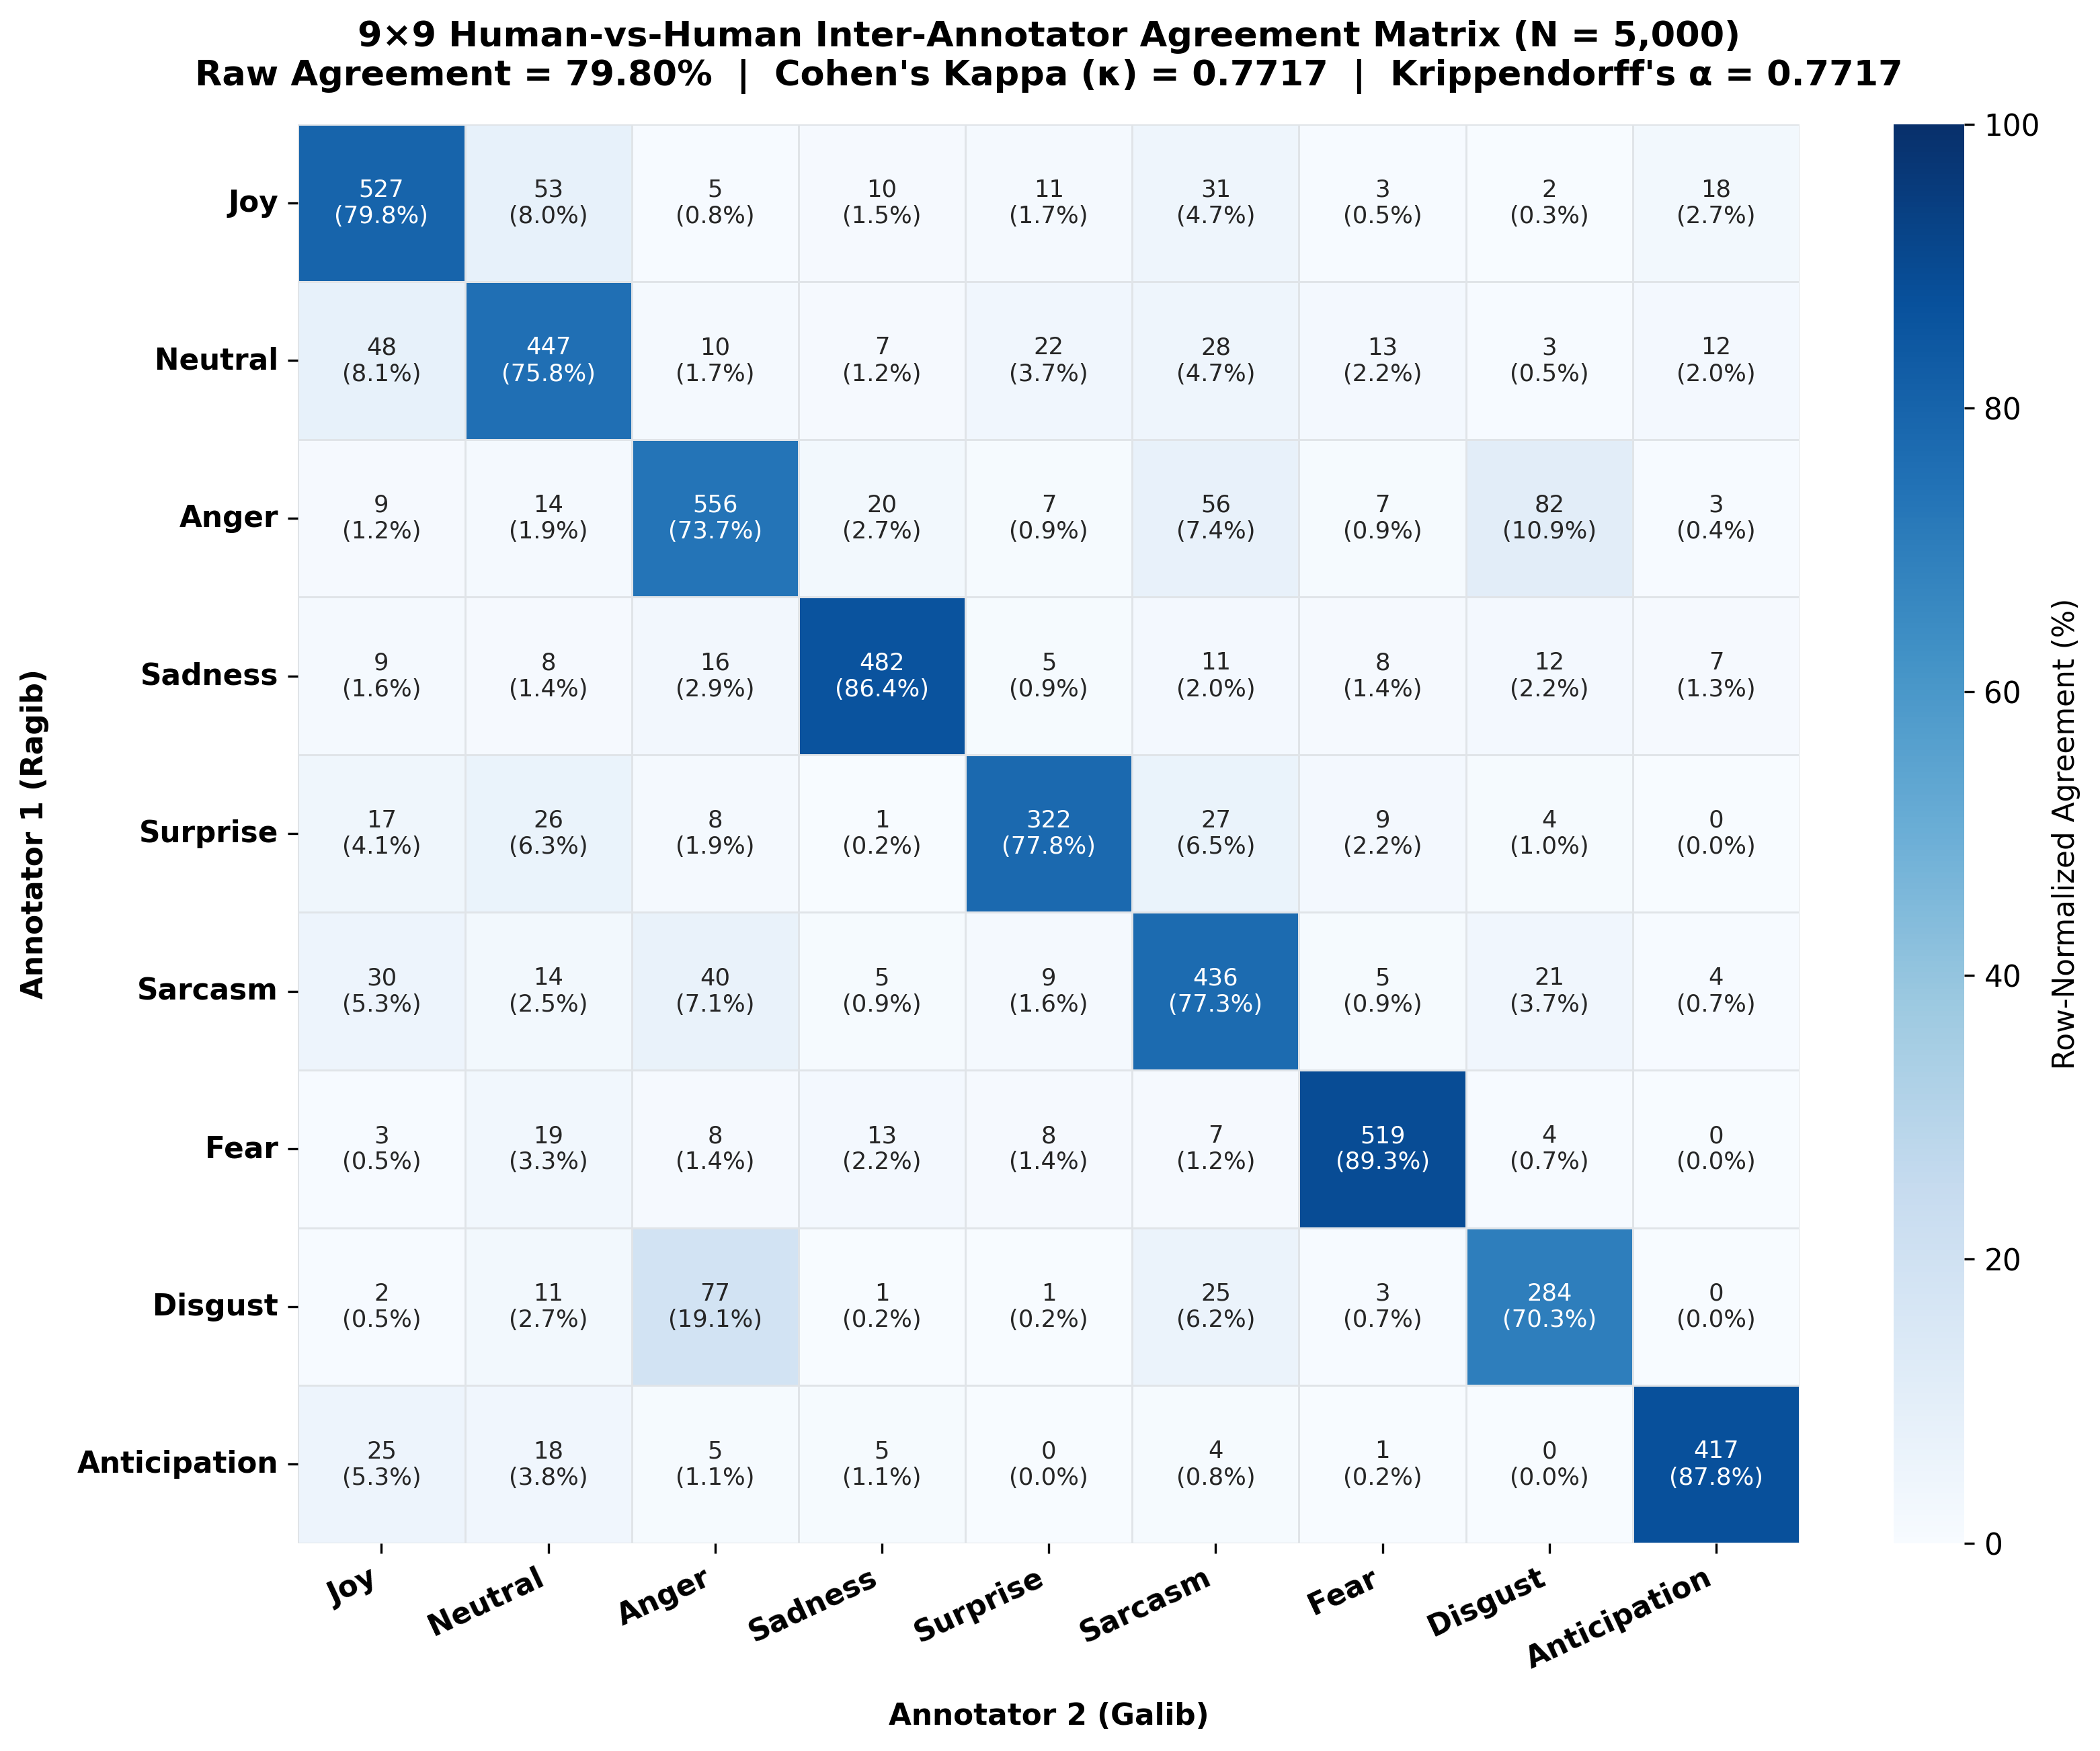

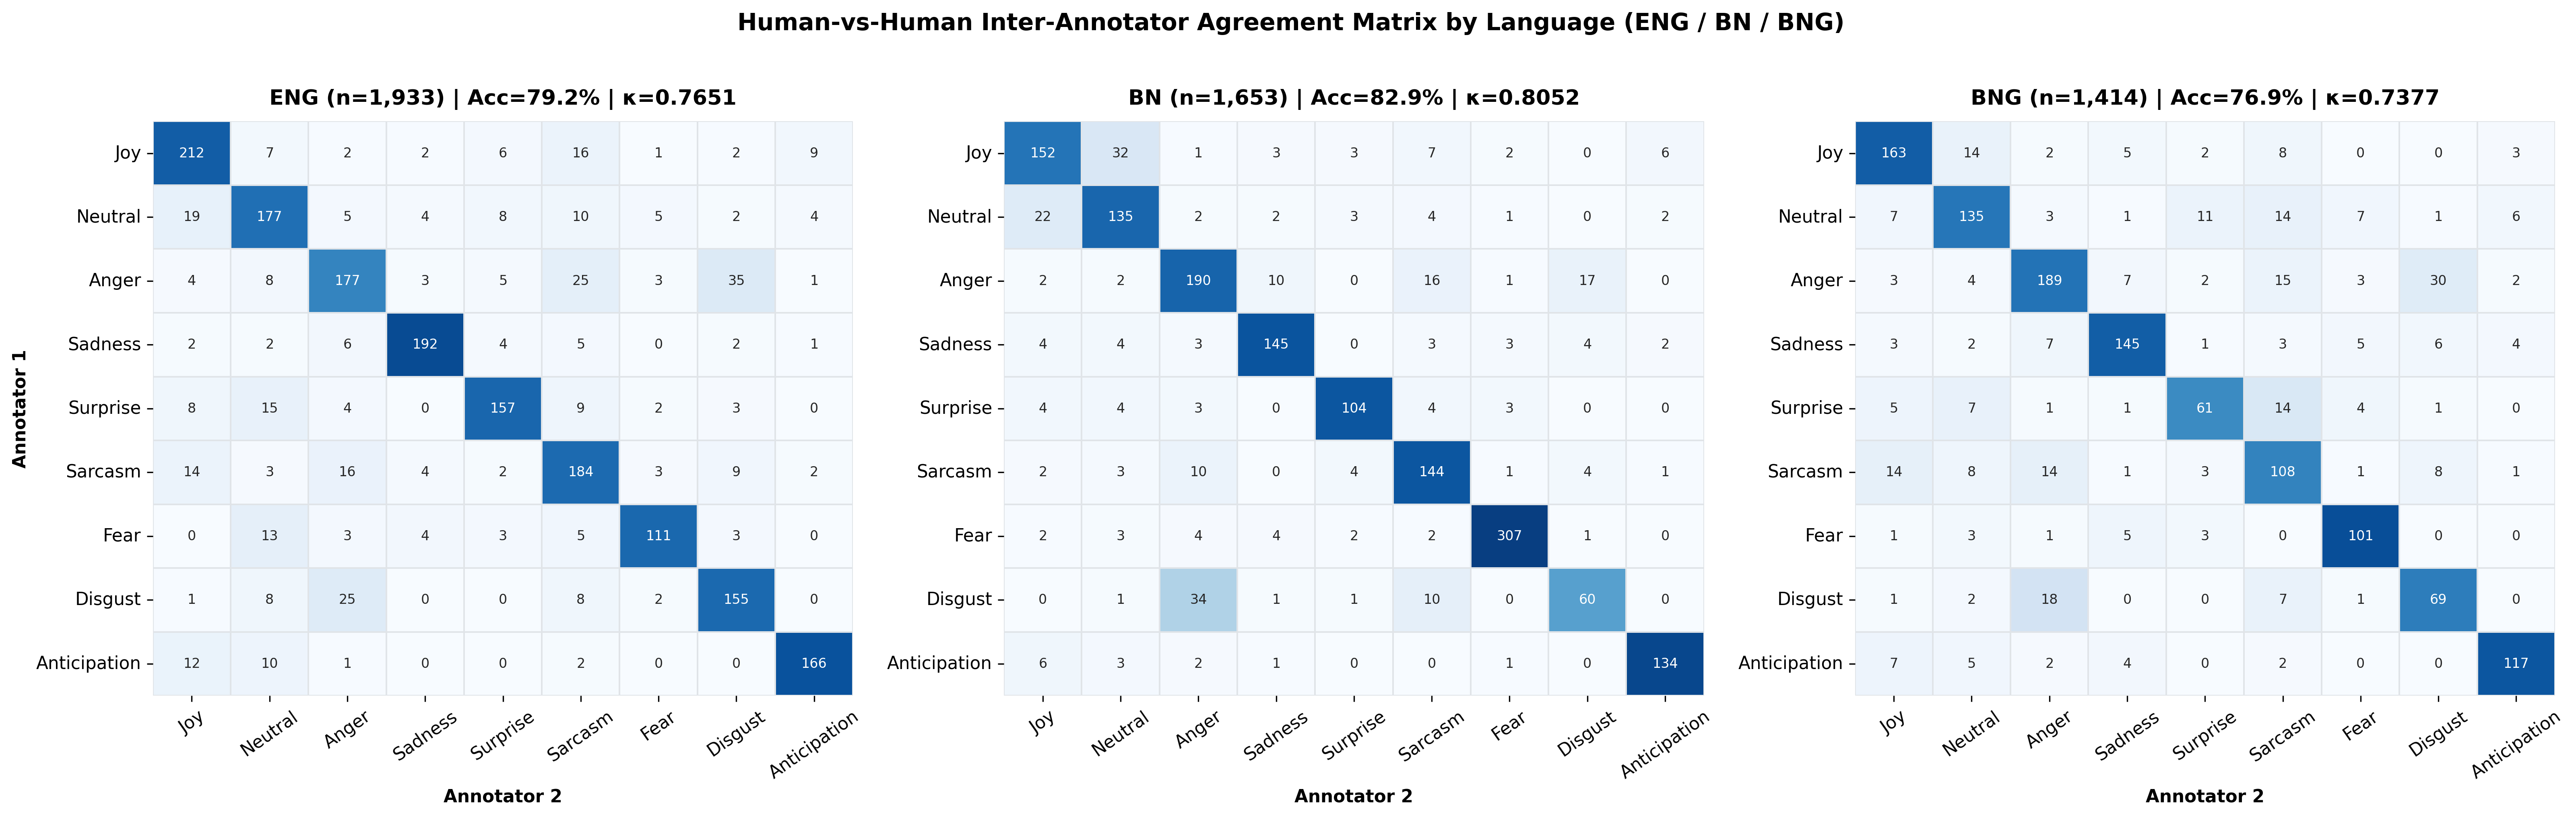

Saved All Agreement Matrix Artifacts to Google Drive:
  1. Overall 9x9 Heatmap PNG : /content/drive/MyDrive/AffectFusion_Day3/02_gold_verification/round2_blind_swap/human_vs_human_5k_agreement_matrix.png
  2. Per-Language 9x9 PNG    : /content/drive/MyDrive/AffectFusion_Day3/02_gold_verification/round2_blind_swap/human_vs_human_5k_matrix_by_language.png
  3. Matrix Counts CSV       : /content/drive/MyDrive/AffectFusion_Day3/02_gold_verification/round2_blind_swap/human_vs_human_5k_matrix_counts.csv
  4. Matrix Percentage CSV   : /content/drive/MyDrive/AffectFusion_Day3/02_gold_verification/round2_blind_swap/human_vs_human_5k_matrix_pct.csv
  5. Top Disagreements CSV   : /content/drive/MyDrive/AffectFusion_Day3/02_gold_verification/round2_blind_swap/human_vs_human_top_disagreement_pairs.csv

Top 10 Human-vs-Human Disagreement Pairs:


,Emotion_Pair,A1_to_A2,A2_to_A1,Total_Disagreements
0,Anger <-> Disgust,82,77,159
1,Joy <-> Neutral,53,48,101
2,Anger <-> Sarcasm,56,40,96
3,Joy <-> Sarcasm,31,30,61
4,Neutral <-> Surprise,22,26,48
5,Sarcasm <-> Disgust,21,25,46
6,Joy <-> Anticipation,18,25,43
7,Neutral <-> Sarcasm,28,14,42
8,Surprise <-> Sarcasm,27,9,36
9,Anger <-> Sadness,20,16,36


In [ ]:
# ==============================================================================
# CELL 3: 9x9 HUMAN-vs-HUMAN AGREEMENT MATRIX (300-DPI HEATMAPS + CSV EXPORTS)
# ==============================================================================
import os, numpy as np, pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import cohen_kappa_score, accuracy_score, confusion_matrix

GOLD_DIR   = '/content/drive/MyDrive/AffectFusion_Day3/02_gold_verification'
ROUND2_DIR = os.path.join(GOLD_DIR, 'round2_blind_swap')
PAIRED_CSV = os.path.join(ROUND2_DIR, 'human_vs_human_5k_paired.csv')
CLASSES    = ["Joy", "Neutral", "Anger", "Sadness", "Surprise", "Sarcasm", "Fear", "Disgust", "Anticipation"]

# Load paired 5,000-row annotations (works even in a fresh Colab session)
if "paired" not in globals():
    assert os.path.exists(PAIRED_CSV), f"Paired CSV not found at {PAIRED_CSV}! Run Cell 2 first."
    paired = pd.read_csv(PAIRED_CSV)

def krippendorff_alpha_nominal(r1, r2, labels):
    idx_map = {c: i for i, c in enumerate(labels)}
    y1 = np.array([idx_map[x] for x in r1])
    y2 = np.array([idx_map[x] for x in r2])
    n = len(y1)
    d_o = np.mean(y1 != y2)
    counts = np.bincount(np.concatenate([y1, y2]), minlength=len(labels)).astype(float)
    tot = 2.0 * n
    d_e = 1.0 - np.sum(counts * (counts - 1.0)) / (tot * (tot - 1.0))
    return 1.0 if d_e == 0 else float(1.0 - d_o / d_e)

# Clean white-background publication style (matches Day 4 charts)
plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "savefig.facecolor": "white",
    "font.family": "DejaVu Sans",
    "font.size": 10.5,
})

y1 = paired["ragib_label"].tolist()
y2 = paired["galib_label"].tolist()
n_total = len(paired)

cm     = confusion_matrix(y1, y2, labels=CLASSES)
cm_pct = cm.astype(float) / np.maximum(cm.sum(axis=1, keepdims=True), 1) * 100.0
kappa  = float(cohen_kappa_score(y1, y2, labels=CLASSES))
alpha  = krippendorff_alpha_nominal(y1, y2, CLASSES)
raw_ac = float(accuracy_score(y1, y2)) * 100.0

# 1. Export Raw Counts & Row-Normalized Percentage Matrices to CSV (Google Drive)
cm_cnt_df = pd.DataFrame(cm, index=[f"Annotator1_{c}" for c in CLASSES], columns=[f"Annotator2_{c}" for c in CLASSES])
cm_pct_df = pd.DataFrame(np.round(cm_pct, 2), index=[f"Annotator1_{c}" for c in CLASSES], columns=[f"Annotator2_{c}" for c in CLASSES])

cnt_csv = os.path.join(ROUND2_DIR, "human_vs_human_5k_matrix_counts.csv")
pct_csv = os.path.join(ROUND2_DIR, "human_vs_human_5k_matrix_pct.csv")
cm_cnt_df.to_csv(cnt_csv, encoding="utf-8-sig")
cm_pct_df.to_csv(pct_csv, encoding="utf-8-sig")

# 2. Plot Overall 9x9 Agreement Matrix Heatmap (300 DPI White Background)
annot_labels = np.array([
    [f"{cm[i, j]}\n({cm_pct[i, j]:.1f}%)" for j in range(len(CLASSES))]
    for i in range(len(CLASSES))
])

fig, ax = plt.subplots(figsize=(11.0, 8.8), dpi=300)
sns.heatmap(
    cm_pct, annot=annot_labels, fmt="", cmap="Blues", vmin=0, vmax=100,
    xticklabels=CLASSES, yticklabels=CLASSES,
    linewidths=0.6, linecolor="#E0E4E8",
    annot_kws={"size": 8.5},
    cbar_kws={"label": "Row-Normalized Agreement (%)"},
    ax=ax
)
ax.set_xlabel("Annotator 2 (Galib)", fontweight="bold", labelpad=10)
ax.set_ylabel("Annotator 1 (Ragib)", fontweight="bold", labelpad=10)
ax.set_title(
    f"9×9 Human-vs-Human Inter-Annotator Agreement Matrix (N = {n_total:,})\n"
    f"Raw Agreement = {raw_ac:.2f}%  |  Cohen's Kappa (κ) = {kappa:.4f}  |  Krippendorff's α = {alpha:.4f}",
    fontweight="bold", pad=14
)
plt.xticks(rotation=25, ha="right", fontweight="bold")
plt.yticks(rotation=0, fontweight="bold")
plt.tight_layout()

png_all = os.path.join(ROUND2_DIR, "human_vs_human_5k_agreement_matrix.png")
fig.savefig(png_all, dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

# 3. Bonus: 3-Panel Per-Language (ENG / BN / BNG) 9x9 Agreement Matrix
fig, axes = plt.subplots(1, 3, figsize=(21.5, 6.6), dpi=300)
for ax_i, lg in zip(axes, ["ENG", "BN", "BNG"]):
    sub = paired[paired["lang"] == lg]
    if len(sub) < 10:
        ax_i.set_title(f"{lg}: Insufficient Rows")
        ax_i.axis("off")
        continue
    cm_l = confusion_matrix(sub["ragib_label"], sub["galib_label"], labels=CLASSES)
    cm_l_pct = cm_l.astype(float) / np.maximum(cm_l.sum(axis=1, keepdims=True), 1) * 100.0
    k_l = float(cohen_kappa_score(sub["ragib_label"], sub["galib_label"], labels=CLASSES))
    a_l = float(accuracy_score(sub["ragib_label"], sub["galib_label"])) * 100.0
    sns.heatmap(
        cm_l_pct, annot=cm_l, fmt="d", cmap="Blues", vmin=0, vmax=100,
        xticklabels=CLASSES, yticklabels=CLASSES,
        linewidths=0.5, linecolor="#E0E4E8", cbar=False,
        annot_kws={"size": 8.0}, ax=ax_i
    )
    ax_i.set_title(f"{lg} (n={len(sub):,}) | Acc={a_l:.1f}% | κ={k_l:.4f}", fontweight="bold", pad=10)
    ax_i.set_xlabel("Annotator 2", fontweight="bold")
    ax_i.set_ylabel("Annotator 1" if lg == "ENG" else "", fontweight="bold")
    ax_i.tick_params(axis="x", rotation=35)
    ax_i.tick_params(axis="y", rotation=0)

plt.suptitle("Human-vs-Human Inter-Annotator Agreement Matrix by Language (ENG / BN / BNG)", fontweight="bold", fontsize=14, y=1.02)
plt.tight_layout()
png_lang = os.path.join(ROUND2_DIR, "human_vs_human_5k_matrix_by_language.png")
fig.savefig(png_lang, dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

# 4. Top 10 Symmetric Disagreement Pairs (for Adjudication & Q2 Paper Discussion)
pair_counts = []
for i in range(len(CLASSES)):
    for j in range(i + 1, len(CLASSES)):
        total_pair = int(cm[i, j] + cm[j, i])
        if total_pair > 0:
            pair_counts.append({
                "Emotion_Pair": f"{CLASSES[i]} <-> {CLASSES[j]}",
                "A1_to_A2": int(cm[i, j]),
                "A2_to_A1": int(cm[j, i]),
                "Total_Disagreements": total_pair,
            })
df_pairs = pd.DataFrame(pair_counts).sort_values("Total_Disagreements", ascending=False).reset_index(drop=True)
pairs_csv = os.path.join(ROUND2_DIR, "human_vs_human_top_disagreement_pairs.csv")
df_pairs.to_csv(pairs_csv, index=False, encoding="utf-8-sig")

print("Saved All Agreement Matrix Artifacts to Google Drive:")
print("  1. Overall 9x9 Heatmap PNG :", png_all)
print("  2. Per-Language 9x9 PNG    :", png_lang)
print("  3. Matrix Counts CSV       :", cnt_csv)
print("  4. Matrix Percentage CSV   :", pct_csv)
print("  5. Top Disagreements CSV   :", pairs_csv)
print("\nTop 10 Human-vs-Human Disagreement Pairs:")
display(df_pairs.head(10))

In [14]:
# ==============================================================================
# CELL 4: VALIDATE ADJUDICATION, LOCK 5K CONSENSUS GOLD & EXPORT Q2 LATEX TABLE
# ==============================================================================
import os, json, shutil, numpy as np, pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import cohen_kappa_score, accuracy_score, confusion_matrix

# 1. Paths (matches Day 3 & Day 4 workspace exactly)
DAY3_DIR   = '/content/drive/MyDrive/AffectFusion_Day3'
SPLITS_DIR = os.path.join(DAY3_DIR, '01_locked_splits')
GOLD_DIR   = os.path.join(DAY3_DIR, '02_gold_verification')
ROUND2_DIR = os.path.join(GOLD_DIR, 'round2_blind_swap')
FINAL_DIR  = os.path.join(DAY3_DIR, '04_feature_engineered_final')
LOGS_DIR   = os.path.join(DAY3_DIR, 'logs')

PAIRED_CSV = os.path.join(ROUND2_DIR, 'human_vs_human_5k_paired.csv')
ADJ_XLSX   = os.path.join(ROUND2_DIR, 'disagreements_to_adjudicate.xlsx')
LABEL_MAP  = os.path.join(FINAL_DIR,  'label_map.json')

CLASSES    = ["Joy", "Neutral", "Anger", "Sadness", "Surprise", "Sarcasm", "Fear", "Disgust", "Anticipation"]
CANON_MAP  = {c.lower(): c for c in CLASSES}

if os.path.exists(LABEL_MAP):
    with open(LABEL_MAP, 'r', encoding='utf-8') as f:
        LABEL2ID = json.load(f)['label2id']
else:
    LABEL2ID = {c: i for i, c in enumerate(CLASSES)}

assert os.path.exists(PAIRED_CSV), f"Missing {PAIRED_CSV}. Run Cell 2 first."
assert os.path.exists(ADJ_XLSX),   f"Missing {ADJ_XLSX}. Run Cell 2 first."

# 2. Load paired 5K table & adjudicated conflicts
paired = pd.read_csv(PAIRED_CSV)
adj    = pd.read_excel(ADJ_XLSX)

paired['row_id'] = paired['row_id'].astype(str).str.strip()
adj['row_id']    = adj['row_id'].astype(str).str.strip()

# Normalize case/whitespace in final_consensus_label
raw_col = adj['final_consensus_label'].fillna('').astype(str).str.strip()
adj['final_consensus_label'] = raw_col.str.lower().map(CANON_MAP).fillna('')

# Strict validation gate — stops safely if any disagreements are unresolved
invalid_mask = ~adj['final_consensus_label'].isin(CLASSES)
if invalid_mask.any():
    bad = adj.loc[invalid_mask, ['row_id', 'ragib_label', 'galib_label', 'final_consensus_label']]
    print(f"[STOP] {len(bad):,} / {len(adj):,} rows in disagreements_to_adjudicate.xlsx are blank or invalid.")
    print("       Valid classes:", CLASSES)
    display(bad.head(15))
    raise ValueError("Complete all rows in 'final_consensus_label' before running Cell 4.")

# Verify every disagreement row_id from paired is accounted for
expected_dis_ids = set(paired.loc[paired['agreed'] == 0, 'row_id'])
adjudicated_ids  = set(adj['row_id'])
missing_ids      = expected_dis_ids - adjudicated_ids
assert len(missing_ids) == 0, f"Missing {len(missing_ids)} disagreement row_ids in {ADJ_XLSX}!"

# 3. Assemble 5,000-row Consensus Gold Master
adj_map = dict(zip(adj['row_id'], adj['final_consensus_label']))

consensus = paired.copy()
consensus['final_consensus_label'] = np.where(
    consensus['agreed'] == 1,
    consensus['ragib_label'],
    consensus['row_id'].map(adj_map)
)
consensus['resolution_source'] = np.where(consensus['agreed'] == 1, 'unanimous', 'adjudicated')

assert consensus['final_consensus_label'].isin(CLASSES).all(), "Unexpected invalid consensus label!"
assert len(consensus) == 5000, f"Expected 5,000 consensus rows, got {len(consensus):,}."

# Track adjudication breakdown (sided with A1 vs A2 vs 3rd label)
dis_df = consensus[consensus['resolution_source'] == 'adjudicated']
adj_stats = {
    'total_adjudicated': int(len(dis_df)),
    'resolved_to_annotator1': int((dis_df['final_consensus_label'] == dis_df['ragib_label']).sum()),
    'resolved_to_annotator2': int((dis_df['final_consensus_label'] == dis_df['galib_label']).sum()),
    'resolved_to_third_class': int(
        ((dis_df['final_consensus_label'] != dis_df['ragib_label']) &
         (dis_df['final_consensus_label'] != dis_df['galib_label'])).sum()
    ),
}

consensus_csv = os.path.join(ROUND2_DIR, 'human_consensus_5k_final.csv')
consensus.to_csv(consensus_csv, index=False, encoding='utf-8-sig')
print(f"[OK] Validated & saved 5,000-row Consensus Gold Master: {consensus_csv}")
print("     Adjudication breakdown:", adj_stats)

# 4. Safe One-Time Backups (preserves Round-1 files before updating)
for base_d, files in [
    (FINAL_DIR,  ['test_3k.csv', 'test_3k.parquet', 'val_3k.csv', 'val_3k.parquet']),
    (SPLITS_DIR, ['test_3k_locked.parquet', 'val_3k_locked.parquet']),
]:
    bkp_d = os.path.join(base_d, 'backup_pre_consensus')
    os.makedirs(bkp_d, exist_ok=True)
    for fn in files:
        src, dst = os.path.join(base_d, fn), os.path.join(bkp_d, fn)
        if os.path.exists(src) and not os.path.exists(dst):
            shutil.copy2(src, dst)
print("[OK] Pre-consensus backups verified in backup_pre_consensus/ folders.")

# 5. Merge Consensus Gold Labels into test_3k & val_3k (Final + Locked Splits)
gold_map = dict(zip(consensus['row_id'], consensus['final_consensus_label']))

def update_final_split(split_name: str):
    pq_path  = os.path.join(FINAL_DIR, f'{split_name}.parquet')
    csv_path = os.path.join(FINAL_DIR, f'{split_name}.csv')
    df = pd.read_parquet(pq_path) if os.path.exists(pq_path) else pd.read_csv(csv_path)
    df['row_id'] = df['row_id'].astype(str).str.strip()

    old_labels = df['label'].astype(str).copy()
    matched    = df['row_id'].isin(gold_map)
    df.loc[matched, 'label']    = df.loc[matched, 'row_id'].map(gold_map)
    df['label_id']              = df['label'].map(LABEL2ID).astype(int)
    df['is_human_verified']     = np.where(matched, 1, df.get('is_human_verified', 0)).astype(int)
    df['is_double_adjudicated'] = matched.astype(int)

    n_changed = int((old_labels != df['label']).sum())
    assert df[['text_stream', 'label', 'label_id']].isna().sum().sum() == 0, f"Nulls found in {split_name}!"

    df.to_parquet(pq_path, index=False)
    df.to_csv(csv_path, index=False, encoding='utf-8-sig')

    # Keep 01_locked_splits synced as well
    locked_pq = os.path.join(SPLITS_DIR, f'{split_name}_locked.parquet')
    if os.path.exists(locked_pq):
        df_l = pd.read_parquet(locked_pq)
        df_l['row_id'] = df_l['row_id'].astype(str).str.strip()
        m_l = df_l['row_id'].isin(gold_map)
        if 'pre_consensus_label' not in df_l.columns:
            df_l['pre_consensus_label'] = df_l['ai_label']
        df_l.loc[m_l, 'ai_label'] = df_l.loc[m_l, 'row_id'].map(gold_map)
        df_l.to_parquet(locked_pq, index=False)

    return df, int(matched.sum()), n_changed

df_test, te_matched, te_changed = update_final_split('test_3k')
df_val,  va_matched, va_changed = update_final_split('val_3k')

print(f"\n[MERGED] test_3k : {te_matched:,}/{len(df_test):,} double-verified ({te_changed:,} labels updated from Round-1)")
print(f"[MERGED] val_3k  : {va_matched:,}/{len(df_val):,} double-verified ({va_changed:,} labels updated from Round-1)")

# 6. Zero-Leakage Integrity Verification Across train_24k / val_3k / test_3k
tr_pq  = os.path.join(FINAL_DIR, 'train_24k.parquet')
tr_csv = os.path.join(FINAL_DIR, 'train_24k.csv')
df_train = pd.read_parquet(tr_pq, columns=['row_id', 'raw_text']) if os.path.exists(tr_pq) else pd.read_csv(tr_csv, usecols=['row_id', 'raw_text'])

tr_ids, va_ids, te_ids = set(df_train['row_id'].astype(str)), set(df_val['row_id']), set(df_test['row_id'])
tr_txt, va_txt, te_txt = set(df_train['raw_text'].astype(str)), set(df_val['raw_text'].astype(str)), set(df_test['raw_text'].astype(str))

assert len(tr_ids & va_ids) == 0 and len(tr_ids & te_ids) == 0 and len(va_ids & te_ids) == 0, "row_id leakage detected!"
assert len(tr_txt & va_txt) == 0 and len(tr_txt & te_txt) == 0 and len(va_txt & te_txt) == 0, "Text leakage detected!"
print("[PASS] Zero row_id and raw_text leakage verified across train_24k, val_3k, and test_3k.")

# 7. Anonymized 300-DPI Heatmap (Ready for Double-Blind Q2 Submission)
def krippendorff_alpha_nominal(r1, r2, labels):
    idx_map = {c: i for i, c in enumerate(labels)}
    y1, y2 = np.array([idx_map[x] for x in r1]), np.array([idx_map[x] for x in r2])
    d_o = np.mean(y1 != y2)
    counts = np.bincount(np.concatenate([y1, y2]), minlength=len(labels)).astype(float)
    tot = 2.0 * len(y1)
    d_e = 1.0 - np.sum(counts * (counts - 1.0)) / (tot * (tot - 1.0))
    return 1.0 if d_e == 0 else float(1.0 - d_o / d_e)

y1, y2 = paired['ragib_label'].tolist(), paired['galib_label'].tolist()
cm     = confusion_matrix(y1, y2, labels=CLASSES)
cm_pct = cm.astype(float) / np.maximum(cm.sum(axis=1, keepdims=True), 1) * 100.0
kappa  = float(cohen_kappa_score(y1, y2, labels=CLASSES))
alpha  = krippendorff_alpha_nominal(y1, y2, CLASSES)
raw_ac = float(accuracy_score(y1, y2)) * 100.0

annot_labels = np.array([[f"{cm[i, j]}\n({cm_pct[i, j]:.1f}%)" for j in range(9)] for i in range(9)])
fig, ax = plt.subplots(figsize=(11.0, 8.8), dpi=300)
sns.heatmap(
    cm_pct, annot=annot_labels, fmt="", cmap="Blues", vmin=0, vmax=100,
    xticklabels=CLASSES, yticklabels=CLASSES,
    linewidths=0.6, linecolor="#E0E4E8", annot_kws={"size": 8.5},
    cbar_kws={"label": "Row-Normalized Agreement (%)"}, ax=ax
)
ax.set_xlabel("Annotator 2", fontweight="bold", labelpad=10)
ax.set_ylabel("Annotator 1", fontweight="bold", labelpad=10)
ax.set_title(
    f"9×9 Human-vs-Human Inter-Annotator Agreement Matrix (N = {len(paired):,})\n"
    f"Raw Agreement = {raw_ac:.2f}%  |  Cohen's Kappa (κ) = {kappa:.4f}  |  Krippendorff's α = {alpha:.4f}",
    fontweight="bold", pad=14
)
plt.xticks(rotation=25, ha="right", fontweight="bold")
plt.yticks(rotation=0, fontweight="bold")
plt.tight_layout()
png_blind = os.path.join(ROUND2_DIR, 'human_vs_human_5k_agreement_matrix_blind.png')
fig.savefig(png_blind, dpi=300, bbox_inches='tight')
plt.close(fig)

# 8. Export LaTeX-Ready Booktabs Table (Overall, By Language, By Split & Per Class)
def slice_metrics(df_sub):
    a, b = df_sub['ragib_label'].tolist(), df_sub['galib_label'].tolist()
    return (
        len(df_sub),
        100.0 * accuracy_score(a, b),
        float(cohen_kappa_score(a, b, labels=CLASSES)),
        krippendorff_alpha_nominal(a, b, CLASSES),
    )

latex_lines = [
    r"\begin{table}[t]",
    r"\centering",
    r"\caption{Human-vs-Human Inter-Annotator Agreement (IAA) Across Languages and Splits ($N = 5{,}000$ Blindly Paired Comments).}",
    r"\label{tab:iaa_summary}",
    r"\begin{tabular}{lrrrr}",
    r"\toprule",
    r"\textbf{Evaluation Slice} & \textbf{Samples ($n$)} & \textbf{Agreement (\%)} & \textbf{Cohen's $\kappa$} & \textbf{Krippendorff's $\alpha$} \\",
    r"\midrule",
]

for label_txt, sub_df in [
    (r"\textbf{Overall (Combined)}", paired),
    (r"\quad Bangla (BN)",           paired[paired['lang'] == 'BN']),
    (r"\quad English (ENG)",         paired[paired['lang'] == 'ENG']),
    (r"\quad Banglish (BNG)",        paired[paired['lang'] == 'BNG']),
    (r"\quad Validation Gold (val\_3k)", paired[paired['source_split'] == 'val_3k']),
    (r"\quad Test Gold (test\_3k)",      paired[paired['source_split'] == 'test_3k']),
]:
    n_s, acc_s, k_s, al_s = slice_metrics(sub_df)
    latex_lines.append(f"{label_txt} & {n_s:,} & {acc_s:.2f}\\% & {k_s:.4f} & {al_s:.4f} \\\\")

latex_lines += [
    r"\midrule",
    r"\multicolumn{5}{l}{\textbf{Per-Class Symmetric F1 Agreement \& One-vs-Rest $\kappa$}} \\",
    r"\textbf{Emotion Class} & \textbf{Final Gold ($n$)} & \textbf{Agreed ($n$)} & \textbf{F1 Agree (\%)} & \textbf{Binary $\kappa$} \\",
    r"\midrule",
]

row_sums, col_sums = cm.sum(axis=1), cm.sum(axis=0)
final_cls_counts = consensus['final_consensus_label'].value_counts().to_dict()
for i, c in enumerate(CLASSES):
    tp, r_t, c_t = int(cm[i, i]), int(row_sums[i]), int(col_sums[i])
    f1_a = 200.0 * tp / (r_t + c_t)
    tn = len(paired) - r_t - c_t + tp
    po = (tp + tn) / len(paired)
    pe = (r_t / len(paired)) * (c_t / len(paired)) + ((len(paired) - r_t) / len(paired)) * ((len(paired) - c_t) / len(paired))
    kc = (po - pe) / (1.0 - pe)
    latex_lines.append(f"{c} & {final_cls_counts.get(c, 0):,} & {tp:,} & {f1_a:.2f}\\% & {kc:.4f} \\\\")

latex_lines += [
    r"\bottomrule",
    r"\end{tabular}",
    r"\end{table}",
]

tex_path = os.path.join(ROUND2_DIR, 'table_iaa_5k_summary.tex')
with open(tex_path, 'w', encoding='utf-8') as f:
    f.write("\n".join(latex_lines))

# Save merge audit JSON
merge_log = {
    'consensus_rows': int(len(consensus)),
    'unanimous_rows': int((consensus['resolution_source'] == 'unanimous').sum()),
    'adjudication_stats': adj_stats,
    'test_3k': {'rows': int(len(df_test)), 'double_verified': te_matched, 'labels_changed_vs_r1': te_changed, 'class_counts': df_test['label'].value_counts().to_dict()},
    'val_3k':  {'rows': int(len(df_val)),  'double_verified': va_matched, 'labels_changed_vs_r1': va_changed, 'class_counts': df_val['label'].value_counts().to_dict()},
    'blind_heatmap_png': png_blind,
    'latex_table_tex': tex_path,
}
log_path = os.path.join(LOGS_DIR, 'consensus_merge_report.json')
with open(log_path, 'w', encoding='utf-8') as f:
    json.dump(merge_log, f, indent=2)

print("\n" + "=" * 80)
print("ALL CONSENSUS GOLD ARTIFACTS SAVED SUCCESSFULLY")
print("=" * 80)
print("  1. Blind 300-DPI Heatmap :", png_blind)
print("  2. LaTeX Q2 IAA Table    :", tex_path)
print("  3. Consensus Audit JSON  :", log_path)
print("\nUpdated Class Distribution (Consensus Gold):")
dist_df = pd.DataFrame({
    'test_3k_gold': df_test['label'].value_counts().reindex(CLASSES, fill_value=0),
    'val_3k_gold':  df_val['label'].value_counts().reindex(CLASSES, fill_value=0),
})
dist_df['total_5k_eval'] = dist_df['test_3k_gold'] + dist_df['val_3k_gold']
display(dist_df)

[OK] Validated & saved 5,000-row Consensus Gold Master: /content/drive/MyDrive/AffectFusion_Day3/02_gold_verification/round2_blind_swap/human_consensus_5k_final.csv
     Adjudication breakdown: {'total_adjudicated': 1010, 'resolved_to_annotator1': 526, 'resolved_to_annotator2': 482, 'resolved_to_third_class': 2}
[OK] Pre-consensus backups verified in backup_pre_consensus/ folders.

[MERGED] test_3k : 3,000/3,000 double-verified (472 labels updated from Round-1)
[MERGED] val_3k  : 2,000/3,000 double-verified (264 labels updated from Round-1)
[PASS] Zero row_id and raw_text leakage verified across train_24k, val_3k, and test_3k.

ALL CONSENSUS GOLD ARTIFACTS SAVED SUCCESSFULLY
  1. Blind 300-DPI Heatmap : /content/drive/MyDrive/AffectFusion_Day3/02_gold_verification/round2_blind_swap/human_vs_human_5k_agreement_matrix_blind.png
  2. LaTeX Q2 IAA Table    : /content/drive/MyDrive/AffectFusion_Day3/02_gold_verification/round2_blind_swap/table_iaa_5k_summary.tex
  3. Consensus Audit JSON  :

,test_3k_gold,val_3k_gold,total_5k_eval
label,,,
Joy,392,348,740
Neutral,385,362,747
Anger,470,431,901
Sadness,333,330,663
Surprise,207,299,506
Sarcasm,367,336,703
Fear,355,339,694
Disgust,218,264,482
Anticipation,273,291,564
